# Histogram-based Outlier Score (HBOS)

In [ ]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# from matplotlib import pyplot as plt
import optuna
from sklearn.metrics import average_precision_score, confusion_matrix
import shap

from pyod.models.combination import aom, moa, average, maximization
from pyod.utils.utility import standardizer
from pyod.models.hbos import HBOS


from src.ML_Utils import (DGP, plot_generated_data, plot_hist, count_stat,
                          evaluate_model, descriptive_stat_threshold, confusion_matrix)

NETWORK_TRAFFIC_PATH = Path.cwd().parent / "data" / "network_traffic" 
NETWORK_TRAFFIC_TRAIN = NETWORK_TRAFFIC_PATH / "df_train.csv"
NETWORK_TRAFFIC_VALID = NETWORK_TRAFFIC_PATH / "df_valid.csv"
NETWORK_TRAFFIC_TEST = NETWORK_TRAFFIC_PATH / "df_hold.csv"

## Load data

In [3]:
df_train = pd.read_csv(NETWORK_TRAFFIC_TRAIN)
X_train = df_train.drop("label", axis=1)
y_train = df_train['label']
# print(y_train)
X_train.head()

,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,frequency_band_energy,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK
0,0.130995,0.325352,64796,80,0.714286,0.0,0.836820,0.621469,False,True,False,False,True,False,False,True,False
1,0.983536,0.341513,25476,443,0.357143,0.0,0.109997,0.462735,True,False,False,False,False,False,True,False,False
2,0.040086,0.812864,7022,80,0.071429,0.0,0.506324,0.734016,True,False,True,False,True,False,False,False,False
3,0.928418,0.725507,60573,80,0.000000,0.0,0.914045,0.923464,True,False,False,False,False,True,False,False,False
4,0.545455,0.323503,30487,53,0.571429,0.0,0.992607,0.590219,False,False,True,False,False,False,False,False,False


In [4]:
df_valid= pd.read_csv(NETWORK_TRAFFIC_VALID)
X_valid = df_valid.drop("label", axis=1)
y_valid = df_valid['label']

In [5]:
df_test= pd.read_csv(NETWORK_TRAFFIC_TEST)
X_test = df_test.drop("label", axis=1)
y_test = df_test['label']

## Step 1: Build the model

In [7]:

n_bins=30
contamination = 0.1
hbos = HBOS(n_bins=n_bins, contamination=contamination)
hbos.fit(X_train)

,n_bins,30
,alpha,0.1
,tol,0.5
,contamination,0.1
Name,Type,Value
bin_edges_,"ndarray[float64](31, 17)","[[ 0. , 0. , 1038. ,..., 0. , 0. , 0. ], [ 0.04, 0.04, 3186.2 ,..., 0.03, 0.03, 0.03], [ 0.07, 0.07, 5334.4 ,..., 0.07, 0.07, 0.07], ..., [ 0.93, 0.93,61187.6 ,..., 0.93, 0.93, 0.93], [ 0.97, 0.97,63335.8 ,..., 0.97, 0.97, 0.97], [ 1. , 1. ,65484. ,..., 1. , 1. , 1. ]]"
decision_scores_,"ndarray[float64](700,)","[-28.87,-29.43,-28.67,...,-29.03,-28.7 ,-27.58]"
hist_,"ndarray[float64](30, 17)","[[ 1.07, 0.6 , 0. ,...,22.24,23.31,22.41], [ 0.94, 0.86, 0. ,..., 0. , 0. , 0. ], [ 0.94, 0.9 , 0. ,..., 0. , 0. , 0. ], ..., [ 1.33, 0.69, 0. ,..., 0. , 0. , 0. ], [ 0.69, 1.07, 0. ,..., 0. , 0. , 0. ], [ 1.25, 0.94, 0. ,..., 7.76, 6.69, 7.59]]"
labels_,"ndarray[int64](700,)","[0,0,0,...,0,0,0]"
threshold_,float64,-26.43


In [53]:
results = evaluate_model(hbos, X_train, X_test)
y_train_scores = results["train_scores"]
y_train_pred = results["train_pred"]

y_test_scores = results["test_scores"]
y_test_pred = results["test_pred"]
threshold = results["threshold"]
results 

{'train_scores': array([-28.86631993, -29.43043875, -28.66625101, -29.54289971,
        -30.07603364, -27.12594001, -26.14766002, -29.6237388 ,
        -24.62892306, -30.42180575, -27.6878958 , -29.20611542,
        -30.89525284, -30.39249467, -28.24982982, -27.08174447,
        -28.39339125, -27.16446032, -27.2530817 , -26.84127626,
        -28.19231387, -29.50336464, -26.23193022, -28.69072917,
        -24.44525688, -28.60760491, -29.79349946, -26.30437327,
        -27.40834803, -28.32294523, -27.55108543, -30.07033105,
        -29.33853924, -28.47946462, -30.20787477, -27.56915115,
        -31.38147207, -32.06230278, -28.43878017, -31.12669301,
        -28.12637034, -28.40258531, -29.98054558, -28.17088099,
        -26.2338003 , -28.26872032, -28.70794215, -28.64556456,
        -27.18834226, -28.46658093, -26.33331679, -28.38465302,
        -28.96932167, -27.78366662, -26.88677702, -29.81758578,
        -27.92693367, -29.20098467, -28.14665198, -28.66513033,
        -27.75463955, -2

## Step 2: Determine the threshold

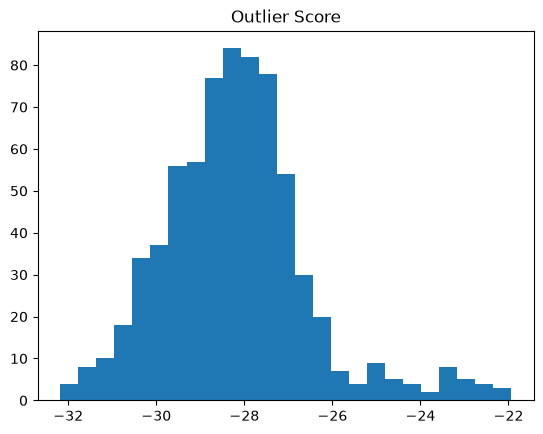

In [13]:
plot_hist(y_train_scores)

## Step 3: Descriptive statistics

In [54]:
descriptive_stat_threshold(X_test,y_test_scores, threshold)

,Group,Count,Count %,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,...,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK,Anomaly_Score
0,Normal,135,90.0,0.53,0.50,33216.85,194.29,0.49,0.0,0.47,...,0.27,0.39,0.23,0.38,0.31,0.37,0.24,0.19,0.29,-28.33
1,Outlier,15,10.0,0.52,0.41,32564.87,216.20,0.58,0.0,0.51,...,0.47,0.47,0.33,0.47,0.47,0.33,0.27,0.33,0.33,-24.81


In [55]:
confusion_matrix(y_train,y_train_scores,threshold)

Pred,0,1
Actual,,
0.0,567,63
1.0,63,7


In [56]:
pr_auc_score_train = average_precision_score(y_train,(y_train_scores>threshold))
pr_auc_score_train

0.1

In [57]:
descriptive_stat_threshold(X_test,y_test_scores, threshold)

,Group,Count,Count %,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,...,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK,Anomaly_Score
0,Normal,135,90.0,0.53,0.50,33216.85,194.29,0.49,0.0,0.47,...,0.27,0.39,0.23,0.38,0.31,0.37,0.24,0.19,0.29,-28.33
1,Outlier,15,10.0,0.52,0.41,32564.87,216.20,0.58,0.0,0.51,...,0.47,0.47,0.33,0.47,0.47,0.33,0.27,0.33,0.33,-24.81


In [58]:
confusion_matrix(y_test,y_test_scores,threshold)

Pred,0,1
Actual,,
0.0,123,12
1.0,12,3


In [59]:
pr_auc_score_test = average_precision_score(y_test,y_test_scores>threshold)
pr_auc_score_test

0.12000000000000002

## Step 4: Averages

In [18]:
def hbos_ensemble(
    X_train,
    X_test,
    k_list=[5,10,15,20,25,30,50,60,75,100],
    contamination=contamination):
    """
    Train multiple HBOS detectors with different numbers
    of histogram bins and combine their anomaly scores
    using score averaging.

    Parameters
    ----------
    X_train : ndarray
        Training dataset.

    X_test : ndarray
        Testing dataset.

    k_list : list, default=[5,10,15,20,25,30,50,60,75,100]
        List of n_bins values used to create diverse
        HBOS models.

    contamination : float, default=0.05
        Expected proportion of anomalies in the data.

    Returns
    -------
    dict
        Dictionary containing ensemble anomaly scores
        for the training and testing datasets.
    """

    # Number of HBOS models in the ensemble
    n_clf = len(k_list)

    # Initialize matrices to store anomaly scores
    # from each HBOS detector
    train_scores = np.zeros(
        (X_train.shape[0], n_clf))

    test_scores = np.zeros(
        (X_test.shape[0], n_clf))

    # Train an HBOS model for each bin configuration
    for i, k in enumerate(k_list):
        # Create and train the HBOS detector
        model = HBOS(n_bins=k,contamination=contamination)
        model.fit(X_train)
        
        # Generate anomaly scores on train and test data
        results = evaluate_model(model,
            X_train,
            X_test)

        # Store scores in the ensemble matrices
        train_scores[:, i] = results["train_scores"]
        test_scores[:, i] = results["test_scores"]

    # Standardize scores because different HBOS models
    # may produce scores on different scales
    train_scores_norm, test_scores_norm = standardizer(
        train_scores,
        test_scores)

    # Average normalized training scores across models
    y_train_combined = average(train_scores_norm)

    # Average normalized testing scores across models
    y_test_combined = average(test_scores_norm)

    # Return ensemble scores
    return {
        "train_scores": y_train_combined,
        "test_scores": y_test_combined
    }

In [19]:
results = hbos_ensemble(X_train, X_test)

y_train_combined = results["train_scores"]
y_test_combined  = results["test_scores"]

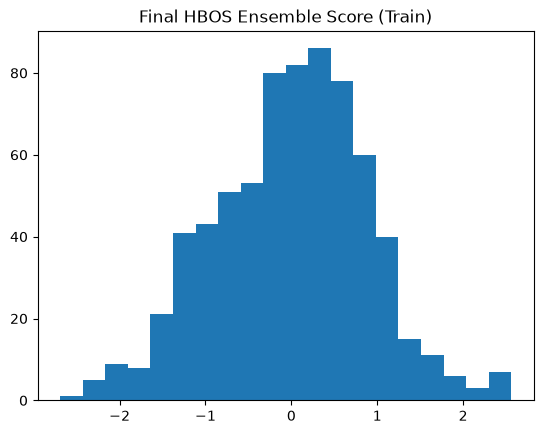

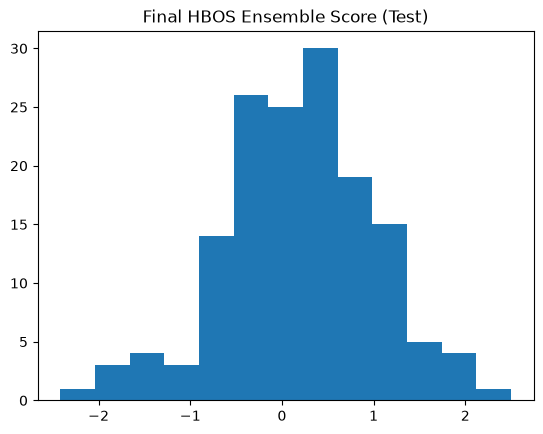

In [20]:
# Plot the histogram of final scores (training data)
plot_hist(y_train_combined, title="Final HBOS Ensemble Score (Train)")

# Optional: plot test scores as well
plot_hist(y_test_combined, title="Final HBOS Ensemble Score (Test)")

In [61]:
descriptive_stat_threshold(X_train,y_train_combined, 1.2)

,Group,Count,Count %,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,...,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK,Anomaly_Score
0,Normal,651,93.0,0.49,0.52,32257.72,195.53,0.50,0.0,0.49,...,0.31,0.35,0.32,0.33,0.33,0.32,0.25,0.22,0.25,-0.13
1,Outlier,49,7.0,0.51,0.44,33828.29,213.04,0.51,0.0,0.53,...,0.49,0.41,0.53,0.39,0.47,0.43,0.43,0.29,0.29,1.67


In [62]:
confusion_matrix(y_train,y_train_combined,threshold=1.2)

Pred,0,1
Actual,,
0.0,587,43
1.0,64,6


In [65]:
pr_auc_score_train = average_precision_score(y_train,(y_train_combined > 0.7),average='weighted')
pr_auc_score_train

0.10555984555984556

In [66]:
descriptive_stat_threshold(X_test,y_test_combined, 0.7)

,Group,Count,Count %,packet_size,inter_arrival_time,src_port,dst_port,packet_count_5s,mean_packet_size,spectral_entropy,...,protocol_type_TCP,protocol_type_UDP,src_ip_192.168.1.2,src_ip_192.168.1.3,dst_ip_192.168.1.5,dst_ip_192.168.1.6,tcp_flags_FIN,tcp_flags_SYN,tcp_flags_SYN-ACK,Anomaly_Score
0,Normal,113,75.333333,0.52,0.49,33480.47,210.01,0.49,0.0,0.46,...,0.22,0.38,0.20,0.34,0.29,0.35,0.22,0.17,0.27,-0.16
1,Outlier,37,24.666667,0.55,0.50,32147.43,155.16,0.53,0.0,0.53,...,0.51,0.46,0.35,0.54,0.43,0.41,0.30,0.32,0.35,1.23


In [68]:
confusion_matrix(y_test,y_test_combined,0.7)

Pred,0,1
Actual,,
0.0,102,33
1.0,11,4


In [69]:
pr_auc_score_test = average_precision_score(y_test,y_test_combined)
pr_auc_score_test

0.15946651267684442